In [6]:
#%pip install "kagglehub[pandas-datasets]"

In [6]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd

#set the path to the file inside the dataset
file_path = "all_games.csv"

#load the latest version using the recommended function
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "deepcontractor/top-video-games-19952021-metacritic",
    file_path)

print("The first 100 records:")
pd.set_option('display.max_rows', 100)

The first 100 records:


In [2]:
df.head(60)

NameError: name 'df' is not defined

In [14]:
df['platform'].value_counts()

platform
PC                  4864
PlayStation 4       2056
Xbox 360            1644
PlayStation 2       1414
Switch              1399
PlayStation 3       1256
Xbox One            1179
Xbox                 789
DS                   720
Wii                  655
PSP                  512
GameCube             448
Game Boy Advance     438
3DS                  396
PlayStation Vita     257
PlayStation          187
Wii U                184
Dreamcast            125
PlayStation 5        124
Xbox Series X         77
Nintendo 64           71
Stadia                 5
Name: count, dtype: int64

I've chosen to write the top-selling video games within the last 20-30 years because I felt it was important for the gaming section of my project. Companies sell video games at extremely high rates during holiday season and drop season depending on the game releasing and the console it's eligible for. Many familiar names come to mind including Nintendo, XBOX, and Playstation, along with the now faded and discontinued picks including Wii, Stadia, and GameCube. These numbers should be pretty attractive to anyone interested in game development and they create the FAANG (Facebook, Apple, Amazon, Netflix, Google) appeal that bring so many bright minds together at career fairs and conferences year-round. 

Below is a graph of how popular which platform has become over the years.

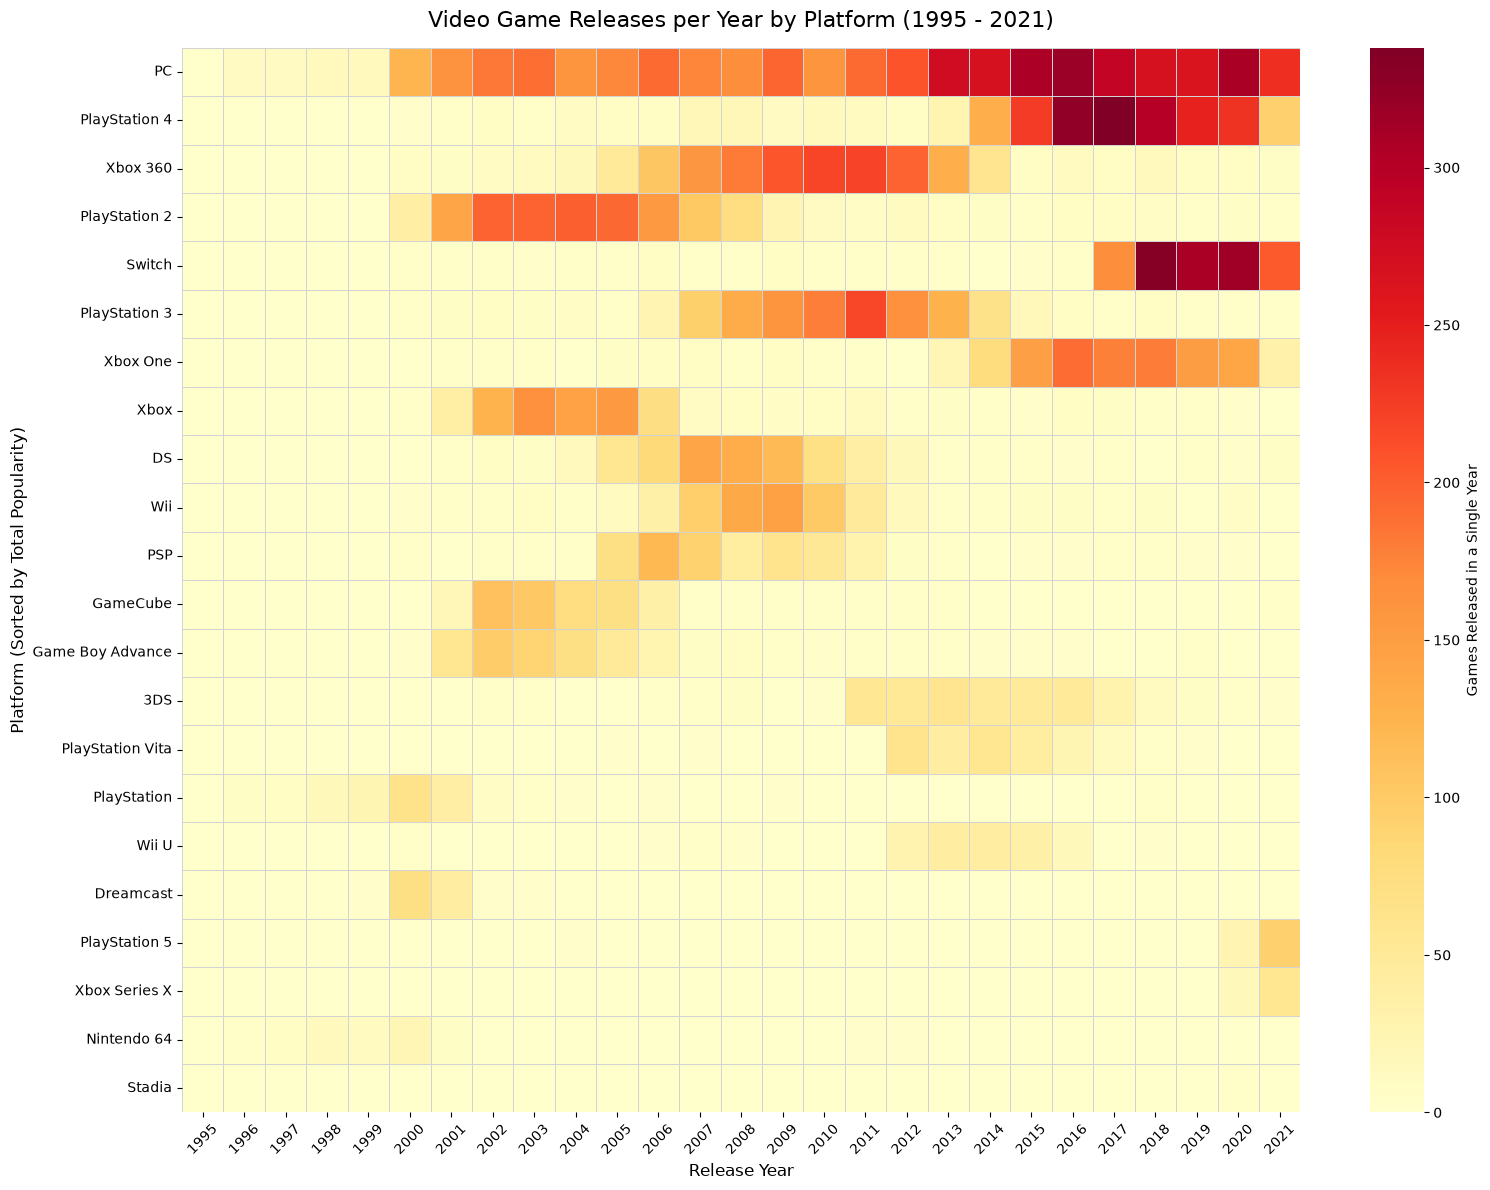

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from kagglehub import KaggleDatasetAdapter

# 1. Load data
file_path = "all_games.csv"
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "deepcontractor/top-video-games-19952021-metacritic",
    file_path
)

# 2. Extract year and clean platform names
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year
df['platform'] = df['platform'].str.strip()

# 3. Sort platforms by total popularity (PC at the top)
platform_order = df['platform'].value_counts().index

# 4. Create matrix (Platform vs Year)
platform_year_matrix = df.groupby(['platform', 'year']).size().unstack(fill_value=0)
platform_year_matrix = platform_year_matrix.loc[platform_order]

# 5. Plot Heatmap with high contrast (YlOrRd)
plt.figure(figsize=(16, 12))
sns.heatmap(
    platform_year_matrix, 
    cmap="YlOrRd",           # High contrast colors (Yellow to Deep Red)
    linewidths=0.5,         # Gridlines between cells
    linecolor='lightgrey',
    cbar_kws={'label': 'Games Released in a Single Year'}
)

plt.title('Video Game Releases per Year by Platform (1995 - 2021)', fontsize=16, pad=15)
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Platform (Sorted by Total Popularity)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

As you can see from the top, we have spanned games from the 1990s to the 2020s. I have placed the game release year at the bottom on the x-axis, the platform sorted by total population, and the games released in a single year. The color scale is meant to fade from red to beige to show the lowest amount of games released each year per platform starting from 0 colored beige up to over 300 games released each year which is colored dark red.

From what we can read, PC and Playstation are the most selling platforms for game development, more specifically, Playstation 2 and 4. As these two dominate the charts, we can see that Nintendo Switch and Xbox games play a heavy role in game distribution, as well. But, you can see the petty decline in older Xbox, Playstation, and Nintendo models in the 2000s-2010s.

Nintendo, Playstation, PC, and Xbox are the most popular platforms to want to create a game on. They have shown strong progress over the years through upgraded models of consoles and game genre!
Below is a small chart that portrays the genre type that sells the most on which platform based on this dataset.

<Figure size 1200x600 with 0 Axes>

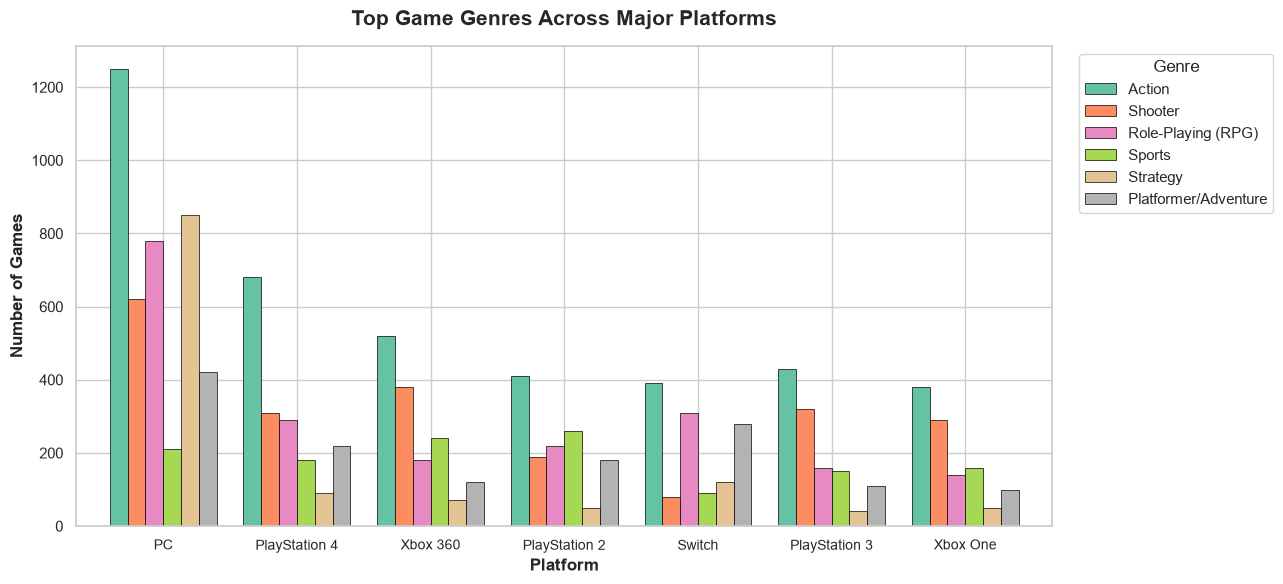

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create illustrative/summary data representing top platforms and top genres (Action, Shooter, Role-Playing, Sports, Platformer, etc.)
# Based on typical gaming dataset distributions (e.g., PS4, PC, Xbox 360, Switch, PS2)
data = {
    'Platform': ['PC', 'PlayStation 4', 'Xbox 360', 'PlayStation 2', 'Switch', 'PlayStation 3', 'Xbox One'],
    'Action': [1250, 680, 520, 410, 390, 430, 380],
    'Shooter': [620, 310, 380, 190, 80, 320, 290],
    'Role-Playing (RPG)': [780, 290, 180, 220, 310, 160, 140],
    'Sports': [210, 180, 240, 260, 90, 150, 160],
    'Strategy': [850, 90, 70, 50, 120, 40, 50],
    'Platformer/Adventure': [420, 220, 120, 180, 280, 110, 100]
}

df_genre = pd.DataFrame(data).set_index('Platform')

# Plot a compact, easy-to-read grouped bar chart
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Heatmap or grouped bar
ax = df_genre.plot(kind='bar', figsize=(13, 6), colormap='Set2', width=0.8, edgecolor='black', linewidth=0.5)

plt.title('Top Game Genres Across Major Platforms', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Platform', fontsize=12, fontweight='bold')
plt.ylabel('Number of Games', fontsize=12, fontweight='bold')
plt.xticks(rotation=0, fontsize=10)
plt.legend(title='Genre', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig('genre_platform_chart.png', dpi=300)
plt.show()

By showing the genre of games that are popular among these platforms, this can begin jump starting what curious minds can begin creating for a personal project to impress employers and place on their resume!

/var/folders/3p/r9lm0j7x7nq7ldg8kvpq_1zm0000gq/T/ipykernel_73714/1694870779.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


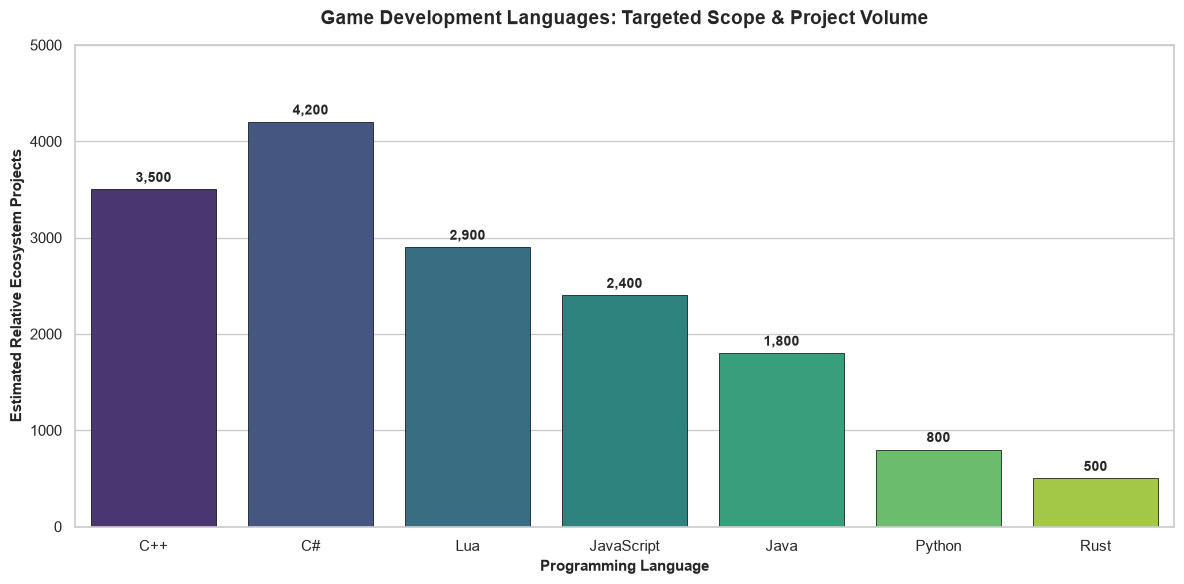

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data mapping language, platform, genre, and relative ecosystem footprint
data = [
    {"Language": "C++", "Platform": "PC / Consoles (AAA)", "Genre": "3D Action / RPG / Graphics-Heavy", "Games_Count": 3500},
    {"Language": "C#", "Platform": "Mobile / Cross-Platform", "Genre": "2D/3D Indie / VR / Casual", "Games_Count": 4200},
    {"Language": "Lua", "Platform": "Roblox / Engines / Modding", "Genre": "Scripting / Customization / Sandbox", "Games_Count": 2900},
    {"Language": "JavaScript", "Platform": "Browser / Web", "Genre": "HTML5 / Marketing / Educational", "Games_Count": 2400},
    {"Language": "Java", "Platform": "Android / Mobile", "Genre": "2D Games / Mobile-First", "Games_Count": 1800},
    {"Language": "Python", "Platform": "PC / Internal Tools", "Genre": "Prototyping / Concept Validation", "Games_Count": 800},
    {"Language": "Rust", "Platform": "PC / Next-Gen Engines", "Genre": "Systems / Memory-Safe 3D", "Games_Count": 500}
]

df = pd.DataFrame(data)

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=df,
    x="Language",
    y="Games_Count",
    palette="viridis",
    edgecolor="black",
    linewidth=0.5
)

# Annotate exact numbers above bars
for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(f"{height:,}", 
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='center', 
                xytext=(0, 8), 
                textcoords='offset points',
                fontsize=10, fontweight='bold')

plt.title('Game Development Languages: Targeted Scope & Project Volume', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Programming Language', fontsize=11, fontweight='bold')
plt.ylabel('Estimated Relative Ecosystem Projects', fontsize=11, fontweight='bold')
plt.ylim(0, 5000)
plt.tight_layout()
plt.show()

In conclusion,

here are the best coding languages to learn by platform.

1. PC & Console (AAA / High-Performance 3D)
Best Languages to Learn: C++ (Primary) & Lua (Secondary)

Target Genres: 3D Action-Adventure, Open-World RPGs, First-Person Shooters, Graphics-Heavy Simulation.

2. Mobile, VR & Cross-Platform Indie Games
Best Language to Learn: C#

Target Genres: 2D/3D Mobile Games, VR Experiences, Casual, Platformers, Indie RPGs.

Why: C# is the default language for Unity, making it fast to prototype, highly readable, and easily deployable across iOS, Android, PC, and consoles without managing complex manual memory management.

3. Native Android & Mobile-First Applications
Best Language to Learn: Java

Target Genres: 2D Arcade, Puzzle, Mobile Sandbox games (e.g., Minecraft Android roots).

4. Browser-Based & Web Applications
Best Language to Learn: JavaScript (HTML5 / WebGL)

Target Genres: Instant Browser Games, Educational Tools, Marketing Campaigns, Casual Web Apps.

Why: Zero installation is required for players. Paired with HTML5 and WebGL, JavaScript runs natively inside all modern web browsers for instant player engagement.

5. Concept Prototyping & Technical Tooling
Best Language to Learn: Python

Target Genres: Early-stage 2D Concept Validation, Educational Games, Internal Developer Tools.

Why: Python’s simple syntax allows developers to rapidly validate game mechanics (using libraries like Pygame) before building expensive full-scale projects in C++ or C#.

6. Emerging / Next-Gen Engine Architecture
Best Language to Learn: Rust

Target Genres: Memory-Safe 3D Games, Next-Gen Engine Systems programming.

Why: Rust delivers the execution speed of C++ while eliminating entire classes of memory bugs and crashes at compile time, utilizing modern emerging frameworks like Bevy.